# 04 — SAE Feature Analysis on PIE

## Objective

Analyze features of the **final independently initialized SAE series** trained on the pretrained PIE model. This notebook adapts the feature-analysis methodology in `external/bio-sae/src/03_analyze_features.py` (Kendiukhov) to PIE activations.

**Provenance.** Only checkpoints listed in `results/sae_training/independent_sae_manifest.json` are allowed. Earlier checkpoints from `runs/sae_expanded/` are preliminary controls and must not be mixed into this analysis.

**PIE-specific interpretation.** Encoder and processor vectors represent latent slots, whereas decoder vectors correspond to output genes. Gene-level feature catalogs can be constructed directly **only for decoder**. The ordered gene symbols are read from `results/gene_reference/gene_index_to_symbol.json`.

This notebook does **not** train SAE models and does **not** repeat PIE inference.


## 1. Input provenance and checkpoint registry

Load the training manifest created by notebook 03 and verify that it names exactly 14 completed, independently initialized SAE runs. The registry is the **single source of truth** for model paths; no directory guessing or "latest run" selection is used. Verification of metadata here is not a substitute for the SHA-256 and weight-integrity checks in notebook 03.

In [6]:
from pathlib import Path
import json
import sys

import h5py
import numpy as np
import torch

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src" / "sae_training.py").is_file():
    PROJECT_ROOT = PROJECT_ROOT.parent

# Make project modules available throughout the notebook.
SRC_DIR = PROJECT_ROOT / "src"

assert (SRC_DIR / "sae_feature_catalog.py").is_file(), (
    f"Missing module: {SRC_DIR / 'sae_feature_catalog.py'}"
)

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))
    
    
assert (PROJECT_ROOT / "src" / "sae_training.py").is_file(), PROJECT_ROOT
assert (PROJECT_ROOT / "external" / "bio-sae" / "src" / "sae_model.py").is_file()

MANIFEST_PATH = PROJECT_ROOT / "results" / "sae_training" / "independent_sae_manifest.json"
GENE_MAP_PATH = PROJECT_ROOT / "results" / "gene_reference" / "gene_index_to_symbol.json"
TRAIN_PATH = PROJECT_ROOT / "data" / "activations" / "expanded_128_32" / "train_128.h5"
VAL_PATH = PROJECT_ROOT / "data" / "activations" / "expanded_128_32" / "val_32.h5"
OUTPUT_DIR = PROJECT_ROOT / "results" / "sae_feature_analysis_independent"

for path in (MANIFEST_PATH, GENE_MAP_PATH, TRAIN_PATH, VAL_PATH):
    assert path.is_file(), f"Missing input: {path}"

manifest = json.loads(MANIFEST_PATH.read_text(encoding="utf-8"))
assert manifest["training_config"]["n_features"] == 3072
assert manifest["training_config"]["topk"] == 32
assert manifest["training_config"]["normalization"] == "original_dim1"

layer_order = (
    [f"encoder.{i}" for i in range(4)]
    + [f"processor.{i}" for i in range(6)]
    + [f"decoder.{i}" for i in range(4)]
)
entries = manifest["checkpoints"]
assert len(entries) == 14
registry = {entry["layer"]: entry for entry in entries}
assert set(registry) == set(layer_order)
assert len({registry[layer]["init_seed"] for layer in layer_order}) == 14

for i, layer in enumerate(layer_order):
    entry = registry[layer]
    assert entry["init_seed"] == 1000 + i
    ckpt = PROJECT_ROOT / entry["checkpoint"]
    assert ckpt.is_file(), ckpt
    assert "sae_protocol_tests" in ckpt.parts, ckpt
    result_path = ckpt.parent / "results.json"
    mean_path = ckpt.parent / "activation_mean.npy"
    assert result_path.is_file() and mean_path.is_file()
    run = json.loads(result_path.read_text(encoding="utf-8"))
    assert run["complete"] and run["config"]["layer"] == layer
    assert run["config"]["init_seed"] == entry["init_seed"]
    assert run["bio_sae_commit"] == manifest["bio_sae_commit"]
    assert abs(run["final_validation"]["r2"] - entry["validation_r2"]) < 1e-8

with h5py.File(VAL_PATH, "r") as f:
    assert f.attrs["split"] == "validation"
    assert int(f.attrs["completed_count"]) == 32
    assert f["gene_ids"].shape == (32, 6642)

with GENE_MAP_PATH.open(encoding="utf-8") as f:
    gene_map = json.load(f)
gene_symbols = gene_map["genes"]
assert len(gene_symbols) == len(set(gene_symbols)) == 6642

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Project root:", PROJECT_ROOT)
print("SAE series: independent, 14 layers")
print("Device:", DEVICE)
print("Gene vocabulary:", len(gene_symbols), "symbols")
for layer in layer_order:
    row = registry[layer]
    print(f"{layer:<13} init={row['init_seed']} | validation R²={row['validation_r2']:.4f}")
print("\nCheckpoint registry validated. No training performed.")

Project root: D:\bio_paper\pie-sae
SAE series: independent, 14 layers
Device: cuda
Gene vocabulary: 6642 symbols
encoder.0     init=1000 | validation R²=0.9821
encoder.1     init=1001 | validation R²=0.9229
encoder.2     init=1002 | validation R²=0.8820
encoder.3     init=1003 | validation R²=0.8473
processor.0   init=1004 | validation R²=0.8440
processor.1   init=1005 | validation R²=0.8340
processor.2   init=1006 | validation R²=0.8256
processor.3   init=1007 | validation R²=0.8224
processor.4   init=1008 | validation R²=0.8161
processor.5   init=1009 | validation R²=0.8119
decoder.0     init=1010 | validation R²=0.8903
decoder.1     init=1011 | validation R²=0.8597
decoder.2     init=1012 | validation R²=0.8352
decoder.3     init=1013 | validation R²=0.8275

Checkpoint registry validated. No training performed.


## 2. Decoder SAE smoke test

Before implementing the feature catalogs, load the decoder.3 SAE using the **exact checkpoint recorded in the manifest**. Encode one held-out perturbation condition (6,642 gene positions) with the training mean. This tests the upstream class interface and the connection between the saved SAE and the validated PIE gene axis.

The output below is a **software sanity check, not a biological result**. We will subsequently follow `bio-sae/src/03_analyze_features.py` by computing feature activation statistics and top-20 associated genes across conditions, with additional checks for the number of conditions supporting a gene–feature association.

In [2]:
UPSTREAM_SRC = PROJECT_ROOT / "external" / "bio-sae" / "src"
if str(UPSTREAM_SRC) not in sys.path:
    sys.path.insert(0, str(UPSTREAM_SRC))
from sae_model import TopKSAE

layer = "decoder.3"
checkpoint_path = PROJECT_ROOT / registry[layer]["checkpoint"]
checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
config = checkpoint["config"]
assert config["layer"] == layer and config["init_seed"] == registry[layer]["init_seed"]
assert config["d_model"] == 768 and config["n_features"] == 3072 and config["topk"] == 32

sae = TopKSAE(d_model=768, n_features=3072, k=32)
sae.load_state_dict(checkpoint["model_state_dict"], strict=True)
sae = sae.to(DEVICE).eval()
mean = np.load(checkpoint_path.parent / "activation_mean.npy")
assert mean.shape == (768,) and np.isfinite(mean).all()
mean_tensor = torch.from_numpy(mean).to(DEVICE)

with h5py.File(VAL_PATH, "r") as f:
    gene_ids = f["gene_ids"][0, :]
    activations = np.asarray(f["decoder"]["3"][0, :, :], dtype=np.float32)
assert activations.shape == (6642, 768)
assert np.array_equal(gene_ids, np.arange(6642, dtype=np.int64))

active_counts = np.zeros(3072, dtype=np.int64)
active_per_gene = []
with torch.inference_mode():
    for start in range(0, 6642, 512):
        tensor = torch.from_numpy(activations[start:start + 512].copy()).to(DEVICE)
        features, _ = sae.encode(tensor - mean_tensor)
        binary = (features > 0)
        active_counts += binary.sum(dim=0).cpu().numpy()
        active_per_gene.append(binary.sum(dim=1).cpu().numpy())

l0 = float(np.concatenate(active_per_gene).mean())
assert abs(l0 - 32.0) < 1e-5, f"Unexpected mean L0: {l0}"
print("Loaded checkpoint:", checkpoint_path.relative_to(PROJECT_ROOT))
print("Matched gene positions:", len(gene_ids))
print("Mean active features per gene position:", l0)
print("Features active at least once in this condition:", int((active_counts > 0).sum()))
print("Decoder SAE smoke test passed. No training performed.")

Loaded checkpoint: runs\sae_protocol_tests\decoder_3_init1013_order42_ep20_bs256_lr3e-04\sae_final.pt
Matched gene positions: 6642
Mean active features per gene position: 32.0
Features active at least once in this condition: 2989
Decoder SAE smoke test passed. No training performed.


## 3. Decoder Feature–Gene Catalogs

Training and validation catalogs are generated for all four PIE decoder blocks using the independently initialized SAE dictionaries. Following the conditional-on-firing ranking used by Kendiukhov, each feature is associated with up to 20 genes having the highest mean positive activation. The count of supporting perturbation conditions is retained for each feature–gene association. Catalogs are descriptive and are not functional annotations.


In [7]:
# --------------------------------------------------
# Feature–gene catalogs for all decoder layers
# --------------------------------------------------

from sae_feature_catalog import build_decoder_catalog

decoder_catalog_results = {}

for layer_index in range(4):

    print("\n" + "=" * 65)
    print(f"DECODER.{layer_index} — FEATURE–GENE CATALOG")
    print("=" * 65)

    result = build_decoder_catalog(
        project_root=PROJECT_ROOT,
        layer_index=layer_index,
        split="train",
        batch_size=256,
        top_genes=20,
    )

    decoder_catalog_results[f"decoder.{layer_index}"] = result

    summary = result["summary"]

    assert summary["n_features"] == 3072
    assert summary["n_conditions"] == 128
    assert summary["n_genes"] == 6642
    assert abs(summary["mean_l0"] - 32.0) < 1e-5

    print(
        f"Completed decoder.{layer_index} | "
        f"Alive: {summary['n_alive']}/3072 | "
        f"Mean L0: {summary['mean_l0']:.2f}"
    )


# --------------------------------------------------
# Final verification
# --------------------------------------------------

assert len(decoder_catalog_results) == 4

print("\n" + "=" * 65)
print("DECODER FEATURE–GENE CATALOG SUMMARY")
print("=" * 65)

for layer_name, result in decoder_catalog_results.items():

    summary = result["summary"]

    print(
        f"{layer_name:<12} | "
        f"Alive: {summary['n_alive']:>4}/3072 | "
        f"Conditions: {summary['n_conditions']:>3} | "
        f"Genes per feature: {summary['top_genes_per_feature']}"
    )

print("\nAll four decoder catalogs are available.")


DECODER.0 — FEATURE–GENE CATALOG
Verified existing feature catalog; skipping recomputation: D:\bio_paper\pie-sae\results\sae_feature_analysis_independent\feature_catalogs\decoder_0_train_catalog.json
Completed decoder.0 | Alive: 3072/3072 | Mean L0: 32.00

DECODER.1 — FEATURE–GENE CATALOG
Verified existing feature catalog; skipping recomputation: D:\bio_paper\pie-sae\results\sae_feature_analysis_independent\feature_catalogs\decoder_1_train_catalog.json
Completed decoder.1 | Alive: 3072/3072 | Mean L0: 32.00

DECODER.2 — FEATURE–GENE CATALOG
Verified existing feature catalog; skipping recomputation: D:\bio_paper\pie-sae\results\sae_feature_analysis_independent\feature_catalogs\decoder_2_train_catalog.json
Completed decoder.2 | Alive: 3072/3072 | Mean L0: 32.00

DECODER.3 — FEATURE–GENE CATALOG
Verified existing feature catalog; skipping recomputation: D:\bio_paper\pie-sae\results\sae_feature_analysis_independent\feature_catalogs\decoder_3_train_catalog.json
Completed decoder.3 | Alive:

### 3.1. Validation of Feature–Gene Associations

Feature–gene catalogs were constructed using the training
perturbation conditions.

To assess the reproducibility of the associations, the same
trained SAEs are applied to 32 held-out validation conditions.

For each decoder layer, we construct an independent catalog
using the same feature activation and gene-ranking procedures.

The analysis evaluates whether the genes associated with
individual SAE features remain consistent across experimental
conditions.

The SAE parameters are fixed throughout this evaluation.

In [8]:
# --------------------------------------------------
# Decoder feature catalogs: validation conditions
# --------------------------------------------------

from sae_feature_catalog import build_decoder_catalog

validation_catalog_results = {}

for layer_index in range(4):

    layer_name = f"decoder.{layer_index}"

    print("\n" + "=" * 60)
    print(f"VALIDATION CATALOG — {layer_name}")
    print("=" * 60)

    result = build_decoder_catalog(
        project_root=PROJECT_ROOT,
        layer_index=layer_index,
        split="validation",
        batch_size=256,
        top_genes=20,
    )

    validation_catalog_results[layer_name] = result

    summary = result["summary"]

    assert summary["n_features"] == 3072
    assert summary["n_conditions"] == 32
    assert summary["n_genes"] == 6642

    assert abs(summary["mean_l0"] - 32.0) < 1e-5

    print(
        f"{layer_name} | "
        f"Alive: {summary['n_alive']}/3072 | "
        f"Inactive: {summary['n_inactive_on_split']} | "
        f"Mean L0: {summary['mean_l0']:.2f}"
    )


assert len(validation_catalog_results) == 4

print("\n" + "=" * 60)
print("VALIDATION CATALOGS COMPLETED")
print("=" * 60)

for layer, result in validation_catalog_results.items():

    summary = result["summary"]

    print(
        f"{layer:<12} | "
        f"Conditions: {summary['n_conditions']} | "
        f"Alive: {summary['n_alive']}/3072"
    )

print("\nAll validation feature catalogs are available.")


VALIDATION CATALOG — decoder.0
Verified existing feature catalog; skipping recomputation: D:\bio_paper\pie-sae\results\sae_feature_analysis_independent\feature_catalogs\decoder_0_validation_catalog.json
decoder.0 | Alive: 3072/3072 | Inactive: 0 | Mean L0: 32.00

VALIDATION CATALOG — decoder.1
Verified existing feature catalog; skipping recomputation: D:\bio_paper\pie-sae\results\sae_feature_analysis_independent\feature_catalogs\decoder_1_validation_catalog.json
decoder.1 | Alive: 3072/3072 | Inactive: 0 | Mean L0: 32.00

VALIDATION CATALOG — decoder.2
Verified existing feature catalog; skipping recomputation: D:\bio_paper\pie-sae\results\sae_feature_analysis_independent\feature_catalogs\decoder_2_validation_catalog.json
decoder.2 | Alive: 3072/3072 | Inactive: 0 | Mean L0: 32.00

VALIDATION CATALOG — decoder.3
Verified existing feature catalog; skipping recomputation: D:\bio_paper\pie-sae\results\sae_feature_analysis_independent\feature_catalogs\decoder_3_validation_catalog.json
deco

### 3.2. Train–Validation Feature–Gene Consistency

We evaluate the reproducibility of gene associations
across independent training and validation conditions.

For each decoder SAE feature, we compare the top-20
associated genes between the two datasets.

The analysis includes:

- Top-20 gene overlap.
- Jaccard similarity.
- Gene-association support across conditions.
- A permutation-based null comparison.

The null model randomly reassigns validation gene lists
to feature identifiers while preserving the distribution
of gene lists within each decoder layer.

The analysis measures statistical consistency of the
feature–gene associations, not biological causality.

In [9]:
import json
import csv
import numpy as np
from pathlib import Path

CATALOG_DIR = (
    PROJECT_ROOT
    / "results"
    / "sae_feature_analysis_independent"
    / "feature_catalogs"
)

OUTPUT_DIR = (
    PROJECT_ROOT
    / "results"
    / "sae_feature_analysis_independent"
    / "consistency"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

N_PERMUTATIONS = 200
rng = np.random.default_rng(42)

results = []
feature_results = []

for layer_index in range(4):

    layer = f"decoder.{layer_index}"

    train_path = (
        CATALOG_DIR / f"decoder_{layer_index}_train_catalog.json"
    )

    val_path = (
        CATALOG_DIR / f"decoder_{layer_index}_validation_catalog.json"
    )

    with open(train_path, encoding="utf-8") as f:
        train_catalog = json.load(f)

    with open(val_path, encoding="utf-8") as f:
        val_catalog = json.load(f)

    train_features = train_catalog["features"]
    val_features = val_catalog["features"]

    assert len(train_features) == len(val_features) == 3072

    # Preserve exact SAE feature identities.
    for j in range(3072):
        assert train_features[j]["feature_idx"] == j
        assert val_features[j]["feature_idx"] == j

    train_sets = []
    val_sets = []

    train_support = []
    val_support = []

    for train_feature, val_feature in zip(
        train_features, val_features
    ):

        t_genes = {
            g["gene_id"]: g["supporting_conditions"]
            for g in train_feature["top_genes"]
        }

        v_genes = {
            g["gene_id"]: g["supporting_conditions"]
            for g in val_feature["top_genes"]
        }

        train_sets.append(set(t_genes))
        val_sets.append(set(v_genes))

        train_support.append(t_genes)
        val_support.append(v_genes)

    overlaps = []
    jaccards = []
    supported_overlaps = []

    for j in range(3072):

        shared = train_sets[j] & val_sets[j]
        union = train_sets[j] | val_sets[j]

        overlap = len(shared)

        jaccard = (
            overlap / len(union)
            if union else 0.0
        )

        # Exploratory support thresholds.
        supported = sum(
            train_support[j][gene_id] >= 5
            and val_support[j][gene_id] >= 3
            for gene_id in shared
        )

        overlaps.append(overlap)
        jaccards.append(jaccard)
        supported_overlaps.append(supported)

        feature_results.append({
            "layer": layer,
            "feature_idx": j,
            "overlap_top20": overlap,
            "jaccard": jaccard,
            "supported_overlap": supported,
        })

    overlaps = np.asarray(overlaps)
    jaccards = np.asarray(jaccards)
    supported_overlaps = np.asarray(supported_overlaps)

    # ------------------------------------------
    # Permutation-based null comparison
    # ------------------------------------------

    null_mean_overlaps = []

    for _ in range(N_PERMUTATIONS):

        permutation = rng.permutation(3072)

        null_overlap = np.mean([
            len(train_sets[j] & val_sets[permutation[j]])
            for j in range(3072)
        ])

        null_mean_overlaps.append(null_overlap)

    null_mean_overlaps = np.asarray(null_mean_overlaps)

    observed = float(overlaps.mean())

    empirical_p = (
        1 + np.sum(null_mean_overlaps >= observed)
    ) / (N_PERMUTATIONS + 1)

    row = {
        "layer": layer,
        "mean_overlap": observed,
        "median_overlap": float(np.median(overlaps)),
        "mean_jaccard": float(jaccards.mean()),
        "median_jaccard": float(np.median(jaccards)),
        "fraction_with_overlap": float(np.mean(overlaps > 0)),
        "mean_supported_overlap": float(
            supported_overlaps.mean()
        ),
        "null_mean_overlap": float(
            null_mean_overlaps.mean()
        ),
        "empirical_p": float(empirical_p),
    }

    results.append(row)

    print("\n" + "=" * 60)
    print(layer.upper())
    print("=" * 60)

    print(f"Mean top-20 overlap: {row['mean_overlap']:.3f}")
    print(f"Median overlap: {row['median_overlap']:.1f}")
    print(f"Mean Jaccard: {row['mean_jaccard']:.4f}")

    print(
        "Features with at least one shared gene:",
        f"{100 * row['fraction_with_overlap']:.1f}%"
    )

    print(
        "Mean supported overlap:",
        f"{row['mean_supported_overlap']:.3f}"
    )

    print(
        "Permutation null mean overlap:",
        f"{row['null_mean_overlap']:.3f}"
    )

    print(f"Permutation p-value: {row['empirical_p']:.4f}")


# ----------------------------------------------
# Save per-feature results
# ----------------------------------------------

feature_path = OUTPUT_DIR / "feature_consistency.csv"

with open(feature_path, "w", newline="", encoding="utf-8") as f:

    writer = csv.DictWriter(
        f,
        fieldnames=list(feature_results[0].keys())
    )

    writer.writeheader()
    writer.writerows(feature_results)


# ----------------------------------------------
# Save layer-level summary
# ----------------------------------------------

summary_path = OUTPUT_DIR / "layer_consistency.json"

with open(summary_path, "w", encoding="utf-8") as f:

    json.dump(
        {
            "n_permutations": N_PERMUTATIONS,
            "support_threshold_train": 5,
            "support_threshold_validation": 3,
            "results": results,
        },
        f,
        indent=2,
    )

print("\n" + "=" * 60)
print("TRAIN–VALIDATION CONSISTENCY COMPLETED")
print("=" * 60)

print("Decoder layers:", len(results))
print("Features evaluated:", len(feature_results))
print("Feature results:", feature_path)
print("Summary:", summary_path)


DECODER.0
Mean top-20 overlap: 19.682
Median overlap: 20.0
Mean Jaccard: 0.9758
Features with at least one shared gene: 99.7%
Mean supported overlap: 19.673
Permutation null mean overlap: 0.067
Permutation p-value: 0.0050

DECODER.1
Mean top-20 overlap: 19.384
Median overlap: 20.0
Mean Jaccard: 0.9590
Features with at least one shared gene: 98.6%
Mean supported overlap: 19.378
Permutation null mean overlap: 0.068
Permutation p-value: 0.0050

DECODER.2
Mean top-20 overlap: 19.075
Median overlap: 20.0
Mean Jaccard: 0.9404
Features with at least one shared gene: 97.9%
Mean supported overlap: 19.058
Permutation null mean overlap: 0.067
Permutation p-value: 0.0050

DECODER.3
Mean top-20 overlap: 18.755
Median overlap: 20.0
Mean Jaccard: 0.9224
Features with at least one shared gene: 97.3%
Mean supported overlap: 18.729
Permutation null mean overlap: 0.068
Permutation p-value: 0.0050

TRAIN–VALIDATION CONSISTENCY COMPLETED
Decoder layers: 4
Features evaluated: 12288
Feature results: D:\bio_

In [10]:
# --------------------------------------------------
# Diagnose near-perfect gene catalog consistency
# --------------------------------------------------

from pathlib import Path
import json
import numpy as np

CATALOG_DIR = (
    PROJECT_ROOT
    / "results"
    / "sae_feature_analysis_independent"
    / "feature_catalogs"
)

print("=" * 70)
print("GENE ASSOCIATION STABILITY DIAGNOSTICS")
print("=" * 70)

for layer_index in range(4):

    catalogs = {}

    for split in ("train", "validation"):

        path = (
            CATALOG_DIR
            / f"decoder_{layer_index}_{split}_catalog.json"
        )

        with open(path, encoding="utf-8") as f:
            catalogs[split] = json.load(f)

        assert catalogs[split]["provenance"]["split"] == split

    train_features = catalogs["train"]["features"]
    val_features = catalogs["validation"]["features"]

    assert len(train_features) == len(val_features) == 3072

    exact_matches = 0
    overlaps = []
    support_train = []
    support_val = []
    stable_80 = []
    full_top20 = 0

    for train_feature, val_feature in zip(
        train_features, val_features
    ):

        assert (
            train_feature["feature_idx"]
            == val_feature["feature_idx"]
        )

        train_genes = {
            g["gene_id"]: g
            for g in train_feature["top_genes"]
        }

        val_genes = {
            g["gene_id"]: g
            for g in val_feature["top_genes"]
        }

        assert all(
            g["mean_activation"] > 0
            and g["supporting_conditions"] > 0
            for g in list(train_genes.values())
            + list(val_genes.values())
        )

        if len(train_genes) == len(val_genes) == 20:
            full_top20 += 1

        shared = train_genes.keys() & val_genes.keys()

        overlaps.append(len(shared))

        if train_genes.keys() == val_genes.keys():
            exact_matches += 1

        for gene_id in shared:

            train_fraction = (
                train_genes[gene_id]["supporting_conditions"]
                / 128
            )

            val_fraction = (
                val_genes[gene_id]["supporting_conditions"]
                / 32
            )

            support_train.append(train_fraction)
            support_val.append(val_fraction)

            stable_80.append(
                train_fraction >= 0.8
                and val_fraction >= 0.8
            )

    print(f"\nDecoder.{layer_index}")
    print("-" * 45)

    print(
        "Features with full top-20 lists:",
        f"{full_top20}/3072"
    )

    print(
        "Exact train/validation gene-set matches:",
        f"{exact_matches}/3072",
        f"({100 * exact_matches / 3072:.2f}%)"
    )

    print(
        "Mean shared genes:",
        f"{np.mean(overlaps):.3f}"
    )

    print(
        "Median train firing fraction (shared genes):",
        f"{np.median(support_train):.4f}"
    )

    print(
        "Median validation firing fraction (shared genes):",
        f"{np.median(support_val):.4f}"
    )

    print(
        "Shared associations firing in >=80% of both splits:",
        f"{100 * np.mean(stable_80):.2f}%"
    )

print("\nDiagnostics completed.")

GENE ASSOCIATION STABILITY DIAGNOSTICS

Decoder.0
---------------------------------------------
Features with full top-20 lists: 3072/3072
Exact train/validation gene-set matches: 2544/3072 (82.81%)
Mean shared genes: 19.682
Median train firing fraction (shared genes): 1.0000
Median validation firing fraction (shared genes): 1.0000
Shared associations firing in >=80% of both splits: 99.79%

Decoder.1
---------------------------------------------
Features with full top-20 lists: 3072/3072
Exact train/validation gene-set matches: 2400/3072 (78.12%)
Mean shared genes: 19.384
Median train firing fraction (shared genes): 1.0000
Median validation firing fraction (shared genes): 1.0000
Shared associations firing in >=80% of both splits: 99.78%

Decoder.2
---------------------------------------------
Features with full top-20 lists: 3070/3072
Exact train/validation gene-set matches: 2217/3072 (72.17%)
Mean shared genes: 19.075
Median train firing fraction (shared genes): 1.0000
Median validati

## 4. SAE Dictionary Geometry

We characterize the geometry of the learned SAE
dictionaries across all 14 PIE Transformer blocks.

For each dictionary, we calculate the mean absolute
pairwise cosine similarity between distinct decoder
directions.

This metric measures the average geometric similarity
between dictionary atoms. It does not establish their
biological interpretation.

The analysis uses the final independently initialized
SAE series.

encoder.0     | MeanCos = 0.03809
encoder.1     | MeanCos = 0.03769
encoder.2     | MeanCos = 0.03862
encoder.3     | MeanCos = 0.04104
processor.0   | MeanCos = 0.04163
processor.1   | MeanCos = 0.04255
processor.2   | MeanCos = 0.04299
processor.3   | MeanCos = 0.04373
processor.4   | MeanCos = 0.04462
processor.5   | MeanCos = 0.04517
decoder.0     | MeanCos = 0.04529
decoder.1     | MeanCos = 0.04491
decoder.2     | MeanCos = 0.04458
decoder.3     | MeanCos = 0.04444


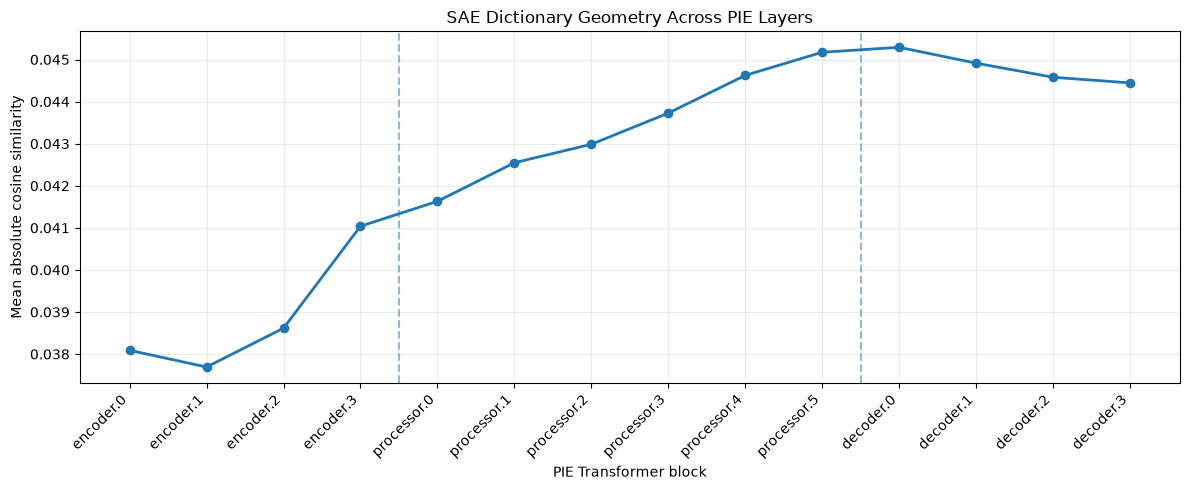


Dictionary geometry analysis completed.
Numerical results: D:\bio_paper\pie-sae\results\sae_feature_analysis_independent\dictionary_geometry\mean_cosine.json
Figure: D:\bio_paper\pie-sae\results\sae_feature_analysis_independent\dictionary_geometry\mean_cosine_by_layer.png


In [11]:
import json

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F


# --------------------------------------------------
# Dictionary geometry for all 14 SAE layers
# --------------------------------------------------

geometry_results = []

with torch.inference_mode():

    for layer in layer_order:

        checkpoint_path = (
            PROJECT_ROOT / registry[layer]["checkpoint"]
        )

        checkpoint = torch.load(
            checkpoint_path,
            map_location="cpu",
            weights_only=True,
        )

        W = checkpoint["model_state_dict"]["W_dec.weight"]

        assert W.shape == (768, 3072)
        assert torch.isfinite(W).all()

        # Decoder dictionary atoms are columns.
        W = W.float().to(DEVICE)

        norms = torch.linalg.vector_norm(W, dim=0)
        assert torch.all(norms > 0)

        atoms = F.normalize(W, p=2, dim=0).T

        cosine_matrix = atoms @ atoms.T

        n = cosine_matrix.shape[0]

        # Exclude self-similarity on the diagonal.
        off_diagonal_sum = (
            cosine_matrix.abs().sum()
            - cosine_matrix.diagonal().abs().sum()
        )

        mean_cosine = (
            off_diagonal_sum / (n * (n - 1))
        ).item()

        assert 0 <= mean_cosine <= 1

        geometry_results.append({
            "layer": layer,
            "mean_abs_cosine": mean_cosine,
            "n_features": n,
            "init_seed": registry[layer]["init_seed"],
        })

        print(
            f"{layer:<13} | "
            f"MeanCos = {mean_cosine:.5f}"
        )


# --------------------------------------------------
# Save numerical results
# --------------------------------------------------

GEOMETRY_DIR = (
    PROJECT_ROOT
    / "results"
    / "sae_feature_analysis_independent"
    / "dictionary_geometry"
)
GEOMETRY_DIR.mkdir(parents=True, exist_ok=True)

results_path = GEOMETRY_DIR / "mean_cosine.json"

with open(results_path, "w", encoding="utf-8") as f:
    json.dump(
        {
            "method": "mean_absolute_pairwise_cosine",
            "diagonal_excluded": True,
            "sae_series": "independent",
            "results": geometry_results,
        },
        f,
        indent=2,
    )


# --------------------------------------------------
# Visualization
# --------------------------------------------------

values = [
    row["mean_abs_cosine"]
    for row in geometry_results
]

x = np.arange(len(layer_order))

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(x, values, marker="o", linewidth=2)

ax.axvline(3.5, linestyle="--", alpha=0.5)
ax.axvline(9.5, linestyle="--", alpha=0.5)

ax.set_xticks(x)
ax.set_xticklabels(layer_order, rotation=45, ha="right")

ax.set_xlabel("PIE Transformer block")
ax.set_ylabel("Mean absolute cosine similarity")
ax.set_title("SAE Dictionary Geometry Across PIE Layers")

ax.grid(alpha=0.25)

fig.tight_layout()

figure_path = GEOMETRY_DIR / "mean_cosine_by_layer.png"

fig.savefig(figure_path, dpi=200, bbox_inches="tight")

plt.show()
plt.close(fig)

assert len(geometry_results) == 14

print("\nDictionary geometry analysis completed.")
print("Numerical results:", results_path)
print("Figure:", figure_path)

## 5. SAE–SVD Alignment

We compare the decoder directions of the independently
initialized SAEs with the leading singular directions
of the corresponding PIE activations.

Following Kendiukhov's feature analysis, the SVD is
computed using up to 50,000 centered training vectors
per layer.

For each SAE feature, we calculate its maximum absolute
cosine similarity with the top 50 singular directions.

The primary alignment threshold is 0.5. We additionally
report results at 0.7 to assess threshold sensitivity.

Single-axis alignment does not measure the total
information captured by a principal subspace.

In [12]:
import json
import h5py
import numpy as np
import torch
import torch.nn.functional as F

SVD_DIR = (
    PROJECT_ROOT
    / "results"
    / "sae_feature_analysis_independent"
    / "svd"
)

SVD_DIR.mkdir(parents=True, exist_ok=True)

SVD_SAMPLE_SIZE = 50_000
N_SVD_AXES = 50


@torch.inference_mode()
def analyze_svd_alignment(layer, seed=42):

    component, index = layer.split(".")

    checkpoint_path = (
        PROJECT_ROOT / registry[layer]["checkpoint"]
    )

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True,
    )

    mean = np.load(
        checkpoint_path.parent / "activation_mean.npy"
    )

    assert mean.shape == (768,)

    # ----------------------------------------------
    # Sample training representations
    # ----------------------------------------------

    rng = np.random.default_rng(seed)

    with h5py.File(TRAIN_PATH, "r") as f:

        dataset = f[component][index]

        n_conditions, n_positions, dim = dataset.shape

        assert dim == 768

        total = n_conditions * n_positions
        n_sample = min(SVD_SAMPLE_SIZE, total)

        selected = np.sort(
            rng.choice(total, n_sample, replace=False)
        )

        X = np.empty((n_sample, dim), dtype=np.float32)

        for condition in range(n_conditions):

            lower = np.searchsorted(
                selected, condition * n_positions
            )

            upper = np.searchsorted(
                selected, (condition + 1) * n_positions
            )

            if lower == upper:
                continue

            positions = (
                selected[lower:upper]
                - condition * n_positions
            )

            X[lower:upper] = dataset[
                condition, positions, :
            ]

    X -= mean

    assert np.isfinite(X).all()

    # ----------------------------------------------
    # Compute right singular directions
    # ----------------------------------------------

    x = torch.from_numpy(X).to(DEVICE)

    covariance = (x.T @ x) / len(x)

    eigenvalues, eigenvectors = torch.linalg.eigh(
        covariance
    )

    eigenvalues = eigenvalues.clamp_min(0)

    directions = eigenvectors[:, -N_SVD_AXES:].flip(
        dims=[1]
    )

    top50_variance = (
        eigenvalues[-N_SVD_AXES:].sum()
        / eigenvalues.sum()
    ).item()

    # ----------------------------------------------
    # SAE dictionary alignment
    # ----------------------------------------------

    W = checkpoint["model_state_dict"]["W_dec.weight"]

    assert W.shape == (768, 3072)

    W = F.normalize(
        W.float().to(DEVICE),
        p=2,
        dim=0,
    )

    cosine = torch.abs(W.T @ directions)

    max_cosine, best_axis = cosine.max(dim=1)

    max_cosine = max_cosine.cpu().numpy()
    best_axis = best_axis.cpu().numpy()

    aligned_05 = int((max_cosine > 0.5).sum())
    aligned_07 = int((max_cosine > 0.7).sum())

    result = {
        "layer": layer,
        "sample_size": n_sample,
        "seed": seed,
        "n_svd_axes": N_SVD_AXES,
        "top50_variance_explained": top50_variance,
        "aligned_threshold_05": aligned_05,
        "aligned_threshold_07": aligned_07,
        "median_max_cosine": float(
            np.median(max_cosine)
        ),
        "p95_max_cosine": float(
            np.percentile(max_cosine, 95)
        ),
    }

    # ----------------------------------------------
    # Save results
    # ----------------------------------------------

    layer_dir = SVD_DIR / layer.replace(".", "_")
    layer_dir.mkdir(parents=True, exist_ok=True)

    np.save(
        layer_dir / "svd_axes.npy",
        directions.T.cpu().numpy(),
    )

    np.savez_compressed(
        layer_dir / "feature_alignment.npz",
        max_cosine=max_cosine,
        best_axis=best_axis,
    )

    with open(
        layer_dir / "summary.json",
        "w",
        encoding="utf-8",
    ) as f:
        json.dump(result, f, indent=2)

    print(f"\n{layer}")
    print("Sampled vectors:", n_sample)
    print(
        "Top-50 variance explained:",
        f"{top50_variance:.4f}"
    )
    print("Aligned features (>0.5):", aligned_05)
    print("Aligned features (>0.7):", aligned_07)
    print(
        "Median maximum cosine:",
        f"{result['median_max_cosine']:.4f}"
    )

    return result


In [13]:
# --------------------------------------------------
# SAE–SVD alignment across all 14 PIE layers
# --------------------------------------------------

import json
import csv
import numpy as np

svd_results = []

for number, layer in enumerate(layer_order, start=1):

    print("\n" + "=" * 65)
    print(f"LAYER {number}/14: {layer}")
    print("=" * 65)

    result = analyze_svd_alignment(
        layer=layer,
        seed=42,
    )

    assert result["layer"] == layer
    assert result["sample_size"] == 50_000

    svd_results.append(result)


# --------------------------------------------------
# Verify completion
# --------------------------------------------------

assert len(svd_results) == 14

assert {
    row["layer"] for row in svd_results
} == set(layer_order)


# --------------------------------------------------
# Save consolidated results
# --------------------------------------------------

summary_path = SVD_DIR / "all_layers_summary.json"

with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(
        {
            "sae_series": "independent",
            "sample_size": 50_000,
            "n_svd_axes": 50,
            "results": svd_results,
        },
        f,
        indent=2,
    )


csv_path = SVD_DIR / "all_layers_summary.csv"

with open(csv_path, "w", newline="", encoding="utf-8") as f:

    writer = csv.DictWriter(
        f,
        fieldnames=list(svd_results[0].keys()),
    )

    writer.writeheader()
    writer.writerows(svd_results)


# --------------------------------------------------
# Display final table
# --------------------------------------------------

print("\n" + "=" * 75)
print("SAE–SVD ALIGNMENT — ALL 14 PIE LAYERS")
print("=" * 75)

print(
    f"{'Layer':<14}"
    f"{'Top50 EV':>12}"
    f"{'Aligned >0.5':>15}"
    f"{'Aligned >0.7':>15}"
)

for row in svd_results:

    print(
        f"{row['layer']:<14}"
        f"{row['top50_variance_explained']:>12.4f}"
        f"{row['aligned_threshold_05']:>15}"
        f"{row['aligned_threshold_07']:>15}"
    )

print("\nTotal layers:", len(svd_results))
print("JSON:", summary_path)
print("CSV:", csv_path)

print("\nSAE–SVD analysis completed for all 14 layers.")


LAYER 1/14: encoder.0

encoder.0
Sampled vectors: 50000
Top-50 variance explained: 0.2920
Aligned features (>0.5): 1
Aligned features (>0.7): 0
Median maximum cosine: 0.1579

LAYER 2/14: encoder.1

encoder.1
Sampled vectors: 50000
Top-50 variance explained: 0.3235
Aligned features (>0.5): 8
Aligned features (>0.7): 1
Median maximum cosine: 0.1661

LAYER 3/14: encoder.2

encoder.2
Sampled vectors: 50000
Top-50 variance explained: 0.3638
Aligned features (>0.5): 7
Aligned features (>0.7): 0
Median maximum cosine: 0.1672

LAYER 4/14: encoder.3

encoder.3
Sampled vectors: 50000
Top-50 variance explained: 0.4294
Aligned features (>0.5): 39
Aligned features (>0.7): 3
Median maximum cosine: 0.1734

LAYER 5/14: processor.0

processor.0
Sampled vectors: 50000
Top-50 variance explained: 0.4513
Aligned features (>0.5): 23
Aligned features (>0.7): 1
Median maximum cosine: 0.1767

LAYER 6/14: processor.1

processor.1
Sampled vectors: 50000
Top-50 variance explained: 0.4687
Aligned features (>0.5):

### 5.1. Layer-wise SAE–SVD Comparison

The SAE–SVD analysis was performed for all 14 PIE blocks
using 50,000 sampled training representations per layer.

We compare:

- The number of SAE features aligned with individual
  leading singular directions at thresholds 0.5 and 0.7.
- The fraction of activation variance explained by the
  top 50 singular directions.

These measurements characterize dictionary geometry
and representation dimensionality. They do not establish
the biological meaning of individual SAE features.

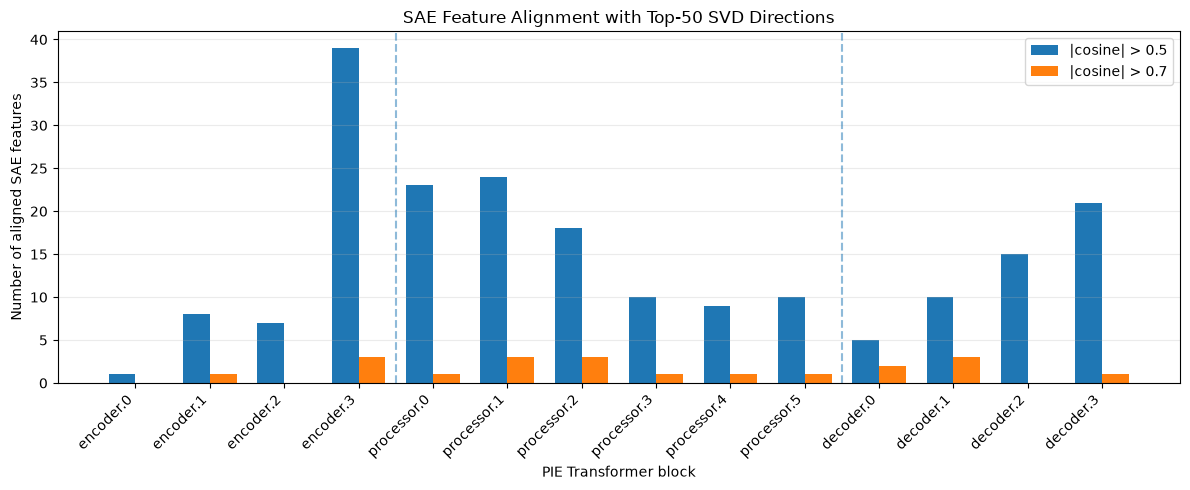

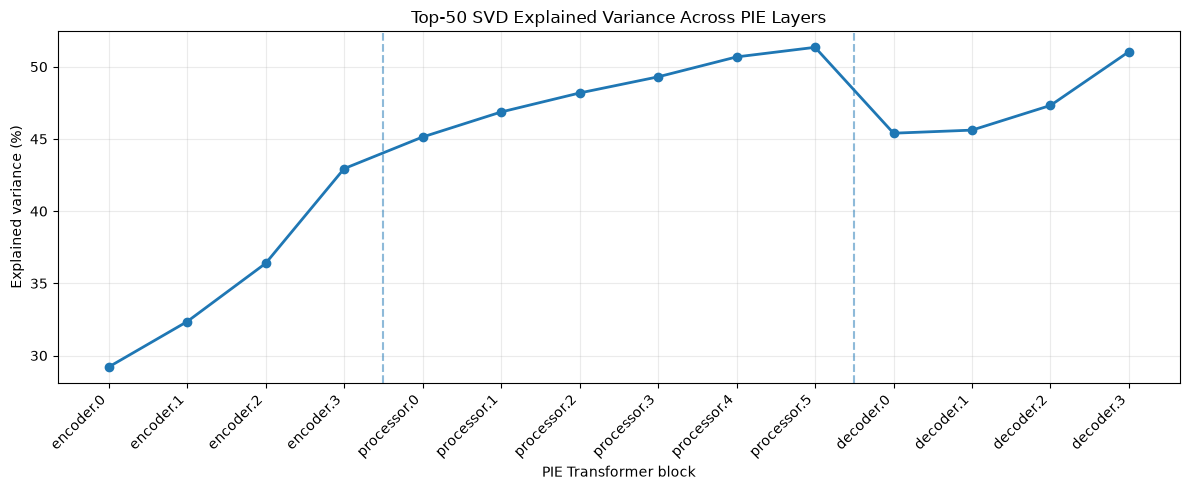

SAE–SVD ALIGNMENT SUMMARY
Total layers: 14
Total features aligned at 0.5: 200
Total features aligned at 0.7: 20

Layer-wise results:
encoder.0     | EV=0.2920 | >0.5:    1 | >0.7:    0
encoder.1     | EV=0.3235 | >0.5:    8 | >0.7:    1
encoder.2     | EV=0.3638 | >0.5:    7 | >0.7:    0
encoder.3     | EV=0.4294 | >0.5:   39 | >0.7:    3
processor.0   | EV=0.4513 | >0.5:   23 | >0.7:    1
processor.1   | EV=0.4687 | >0.5:   24 | >0.7:    3
processor.2   | EV=0.4818 | >0.5:   18 | >0.7:    3
processor.3   | EV=0.4930 | >0.5:   10 | >0.7:    1
processor.4   | EV=0.5068 | >0.5:    9 | >0.7:    1
processor.5   | EV=0.5135 | >0.5:   10 | >0.7:    1
decoder.0     | EV=0.4540 | >0.5:    5 | >0.7:    2
decoder.1     | EV=0.4561 | >0.5:   10 | >0.7:    3
decoder.2     | EV=0.4732 | >0.5:   15 | >0.7:    0
decoder.3     | EV=0.5105 | >0.5:   21 | >0.7:    1

Figures saved:
D:\bio_paper\pie-sae\results\sae_feature_analysis_independent\svd\svd_feature_alignment_by_layer.png
D:\bio_paper\pie-sae\r

In [14]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt


# --------------------------------------------------
# 1. Load saved SVD results
# --------------------------------------------------

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

SVD_DIR = (
    PROJECT_ROOT
    / "results"
    / "sae_feature_analysis_independent"
    / "svd"
)

summary_path = SVD_DIR / "all_layers_summary.json"

with open(summary_path, encoding="utf-8") as f:
    summary = json.load(f)

rows = summary["results"]

assert len(rows) == 14

expected_layers = (
    [f"encoder.{i}" for i in range(4)]
    + [f"processor.{i}" for i in range(6)]
    + [f"decoder.{i}" for i in range(4)]
)

rows_by_layer = {
    row["layer"]: row
    for row in rows
}

assert set(rows_by_layer) == set(expected_layers)

rows = [
    rows_by_layer[layer]
    for layer in expected_layers
]


# --------------------------------------------------
# 2. Extract metrics
# --------------------------------------------------

layers = [row["layer"] for row in rows]

aligned_05 = np.array([
    row["aligned_threshold_05"]
    for row in rows
])

aligned_07 = np.array([
    row["aligned_threshold_07"]
    for row in rows
])

variance = np.array([
    row["top50_variance_explained"]
    for row in rows
])

assert np.all(aligned_07 <= aligned_05)
assert np.all((variance >= 0) & (variance <= 1))

x = np.arange(14)


# --------------------------------------------------
# 3. SAE feature alignment figure
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 5))

width = 0.36

ax.bar(
    x - width / 2,
    aligned_05,
    width,
    label="|cosine| > 0.5",
)

ax.bar(
    x + width / 2,
    aligned_07,
    width,
    label="|cosine| > 0.7",
)

ax.axvline(3.5, linestyle="--", alpha=0.5)
ax.axvline(9.5, linestyle="--", alpha=0.5)

ax.set_xticks(x)
ax.set_xticklabels(layers, rotation=45, ha="right")

ax.set_ylabel("Number of aligned SAE features")
ax.set_xlabel("PIE Transformer block")

ax.set_title(
    "SAE Feature Alignment with Top-50 SVD Directions"
)

ax.legend()
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()

alignment_figure = (
    SVD_DIR / "svd_feature_alignment_by_layer.png"
)

fig.savefig(
    alignment_figure,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)


# --------------------------------------------------
# 4. Top-50 explained variance figure
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    x,
    100 * variance,
    marker="o",
    linewidth=2,
)

ax.axvline(3.5, linestyle="--", alpha=0.5)
ax.axvline(9.5, linestyle="--", alpha=0.5)

ax.set_xticks(x)
ax.set_xticklabels(layers, rotation=45, ha="right")

ax.set_xlabel("PIE Transformer block")
ax.set_ylabel("Explained variance (%)")

ax.set_title(
    "Top-50 SVD Explained Variance Across PIE Layers"
)

ax.grid(alpha=0.25)

fig.tight_layout()

variance_figure = (
    SVD_DIR / "svd_explained_variance_by_layer.png"
)

fig.savefig(
    variance_figure,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)


# --------------------------------------------------
# 5. Summary
# --------------------------------------------------

print("=" * 65)
print("SAE–SVD ALIGNMENT SUMMARY")
print("=" * 65)

print("Total layers:", len(rows))

print(
    "Total features aligned at 0.5:",
    int(aligned_05.sum()),
)

print(
    "Total features aligned at 0.7:",
    int(aligned_07.sum()),
)

print("\nLayer-wise results:")

for i, layer in enumerate(layers):
    print(
        f"{layer:<13} | "
        f"EV={variance[i]:.4f} | "
        f">0.5: {aligned_05[i]:>4} | "
        f">0.7: {aligned_07[i]:>4}"
    )

print("\nFigures saved:")
print(alignment_figure)
print(variance_figure)

print("\nSVD visualization completed.")

## 6. Layer-wise SAE Feature Statistics

Feature activation statistics are computed for all 14 PIE
Transformer blocks using the independently initialized SAEs.

The analysis uses 32 held-out validation conditions and
reports:

- Feature activation frequency.
- Number of inactive features.
- Mean positive activation amplitude.
- Distribution of feature utilization.
- Gini coefficient of activation frequencies.

These metrics characterize the utilization of learned SAE
features and allow comparisons across architectural blocks.

Encoder/processor and decoder statistics are interpreted
separately because their positions represent different
types of objects.

In [15]:
import sys

SRC_DIR = PROJECT_ROOT / "src"

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from sae_activation_stats import analyze_feature_statistics

feature_statistics = analyze_feature_statistics(
    project_root=PROJECT_ROOT,
    batch_size=256,
)

assert len(feature_statistics["results"]) == 14

print("\nFeature statistics completed for all 14 layers.")

encoder.0     | N= 16384 | median freq=0.00848 | Gini=0.3248 | median amplitude=5.883 | inactive=0
encoder.1     | N= 16384 | median freq=0.00635 | Gini=0.4649 | median amplitude=7.034 | inactive=0
encoder.2     | N= 16384 | median freq=0.00598 | Gini=0.5232 | median amplitude=7.724 | inactive=0
encoder.3     | N= 16384 | median freq=0.00525 | Gini=0.5614 | median amplitude=8.237 | inactive=0
processor.0   | N= 16384 | median freq=0.00525 | Gini=0.5659 | median amplitude=8.447 | inactive=0
processor.1   | N= 16384 | median freq=0.00497 | Gini=0.5686 | median amplitude=8.626 | inactive=0
processor.2   | N= 16384 | median freq=0.00519 | Gini=0.5578 | median amplitude=8.630 | inactive=0
processor.3   | N= 16384 | median freq=0.00507 | Gini=0.5648 | median amplitude=8.831 | inactive=0
processor.4   | N= 16384 | median freq=0.00525 | Gini=0.5627 | median amplitude=8.993 | inactive=0
processor.5   | N= 16384 | median freq=0.00543 | Gini=0.5510 | median amplitude=8.922 | inactive=0
decoder.0 

### 6.1. Layer-wise Feature Utilization

We examine changes in SAE feature utilization across the
14 PIE Transformer blocks.

The analysis includes:

- Gini coefficient of feature activation frequencies.
- Median feature activation frequency.
- Median positive feature activation amplitude.

All statistics are computed on the held-out validation
conditions using the independently initialized SAE series.

Architectural transitions are indicated separately to
distinguish encoder, processor, and decoder representations.

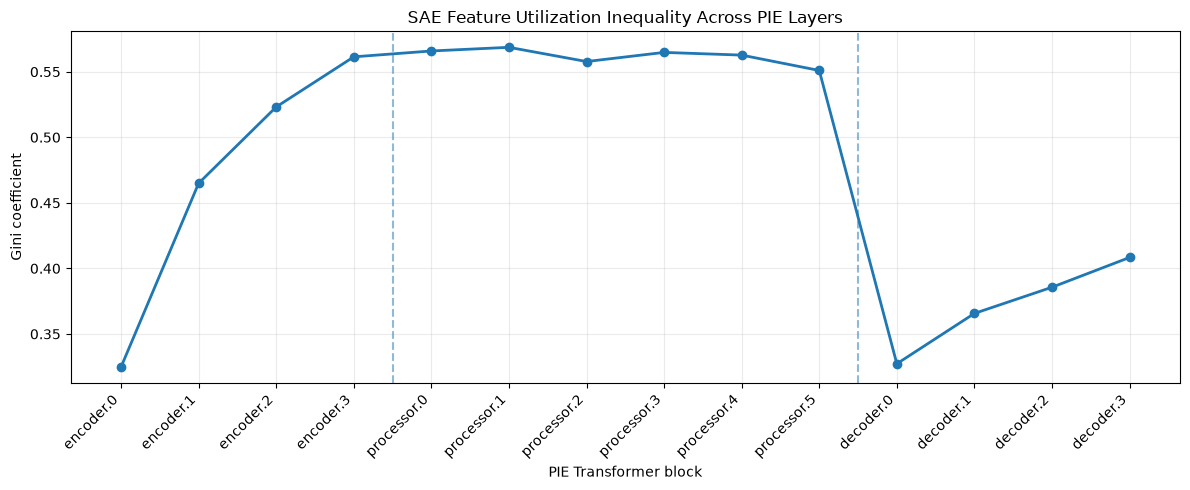

Saved: D:\bio_paper\pie-sae\results\sae_feature_analysis_independent\feature_statistics\figures\feature_gini_by_layer.png


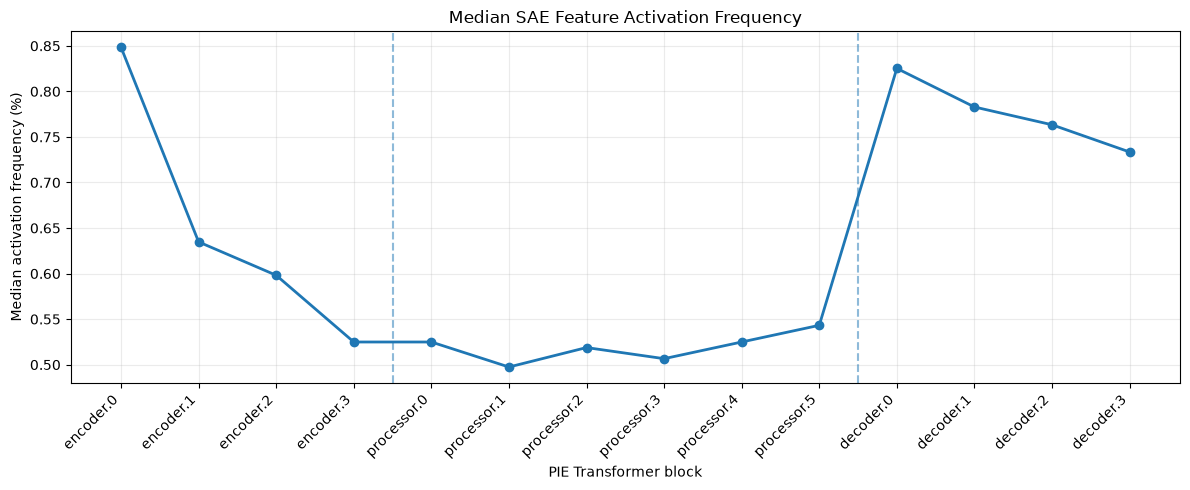

Saved: D:\bio_paper\pie-sae\results\sae_feature_analysis_independent\feature_statistics\figures\median_frequency_by_layer.png


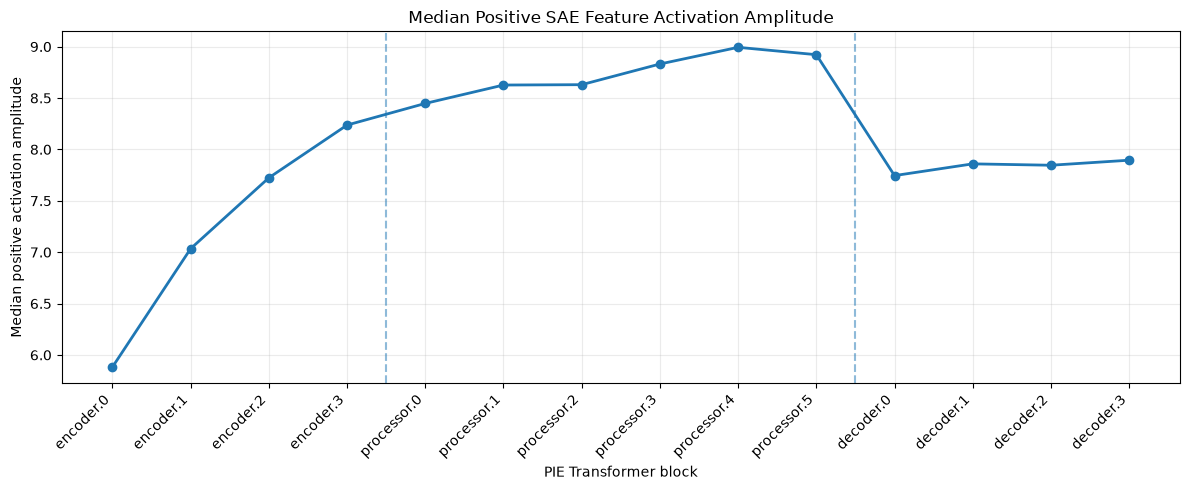

Saved: D:\bio_paper\pie-sae\results\sae_feature_analysis_independent\feature_statistics\figures\median_amplitude_by_layer.png

Feature utilization visualization completed.


In [16]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt


# --------------------------------------------------
# 1. Load feature statistics
# --------------------------------------------------

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

STATS_DIR = (
    PROJECT_ROOT
    / "results"
    / "sae_feature_analysis_independent"
    / "feature_statistics"
)

summary_path = STATS_DIR / "summary.json"

with open(summary_path, encoding="utf-8") as f:
    summary = json.load(f)

assert summary["series"] == "independent"

rows = summary["results"]

assert len(rows) == 14

layer_order = (
    [f"encoder.{i}" for i in range(4)]
    + [f"processor.{i}" for i in range(6)]
    + [f"decoder.{i}" for i in range(4)]
)

rows_by_layer = {
    row["layer"]: row
    for row in rows
}

assert set(rows_by_layer) == set(layer_order)

rows = [
    rows_by_layer[layer]
    for layer in layer_order
]


# --------------------------------------------------
# 2. Extract metrics
# --------------------------------------------------

gini = np.array([
    row["frequency_gini"]
    for row in rows
])

median_frequency = np.array([
    row["median_frequency"]
    for row in rows
])

median_amplitude = np.array([
    row["median_feature_amplitude"]
    for row in rows
])

assert np.isfinite(gini).all()
assert np.isfinite(median_frequency).all()
assert np.isfinite(median_amplitude).all()

x = np.arange(14)


# --------------------------------------------------
# 3. Visualization helper
# --------------------------------------------------

FIGURE_DIR = STATS_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)


def plot_layer_metric(values, title, ylabel, filename):

    fig, ax = plt.subplots(figsize=(12, 5))

    ax.plot(
        x,
        values,
        marker="o",
        linewidth=2,
    )

    # Architectural boundaries
    ax.axvline(
        3.5,
        linestyle="--",
        alpha=0.5,
    )

    ax.axvline(
        9.5,
        linestyle="--",
        alpha=0.5,
    )

    ax.set_xticks(x)

    ax.set_xticklabels(
        layer_order,
        rotation=45,
        ha="right",
    )

    ax.set_xlabel("PIE Transformer block")
    ax.set_ylabel(ylabel)
    ax.set_title(title)

    ax.grid(alpha=0.25)

    fig.tight_layout()

    figure_path = FIGURE_DIR / filename

    fig.savefig(
        figure_path,
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)

    print("Saved:", figure_path)


# --------------------------------------------------
# 4. Gini coefficient
# --------------------------------------------------

plot_layer_metric(
    values=gini,
    title="SAE Feature Utilization Inequality Across PIE Layers",
    ylabel="Gini coefficient",
    filename="feature_gini_by_layer.png",
)


# --------------------------------------------------
# 5. Median activation frequency
# --------------------------------------------------

plot_layer_metric(
    values=100 * median_frequency,
    title="Median SAE Feature Activation Frequency",
    ylabel="Median activation frequency (%)",
    filename="median_frequency_by_layer.png",
)


# --------------------------------------------------
# 6. Positive activation amplitude
# --------------------------------------------------

plot_layer_metric(
    values=median_amplitude,
    title="Median Positive SAE Feature Activation Amplitude",
    ylabel="Median positive activation amplitude",
    filename="median_amplitude_by_layer.png",
)


# --------------------------------------------------
# 7. Final verification
# --------------------------------------------------

figures = list(FIGURE_DIR.glob("*.png"))

for filename in [
    "feature_gini_by_layer.png",
    "median_frequency_by_layer.png",
    "median_amplitude_by_layer.png",
]:
    assert (FIGURE_DIR / filename).is_file()

print("\nFeature utilization visualization completed.")

### 6.2. Distribution of Feature Activation Frequencies

We examine the complete distribution of SAE feature activation
frequencies across selected PIE layers.

For each architectural component, the first and last blocks
are compared using logarithmically spaced frequency bins.

The distributions complement the median frequency and Gini
statistics by revealing differences in feature utilization.

encoder.0     | Median=0.00848 | Inactive=0
encoder.3     | Median=0.00525 | Inactive=0


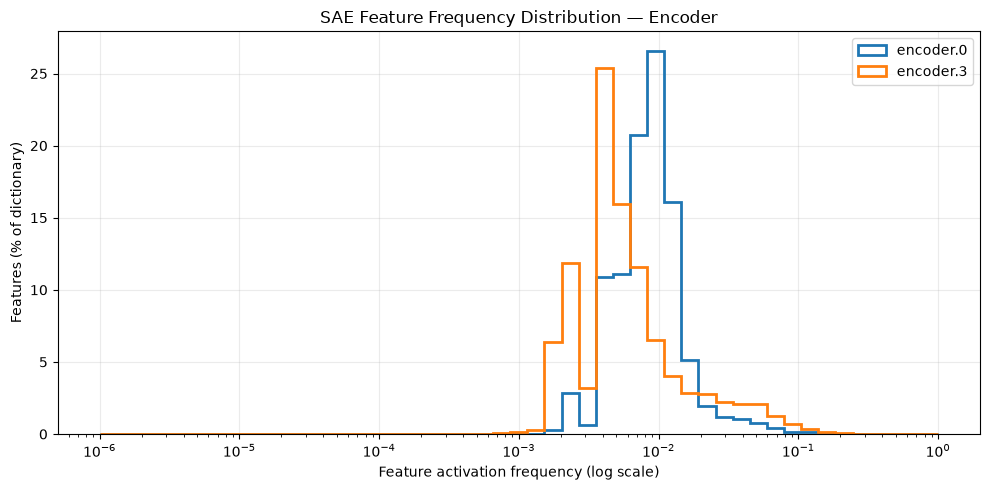

Saved: D:\bio_paper\pie-sae\results\sae_feature_analysis_independent\feature_statistics\figures\encoder_frequency_distribution.png 

processor.0   | Median=0.00525 | Inactive=0
processor.5   | Median=0.00543 | Inactive=0


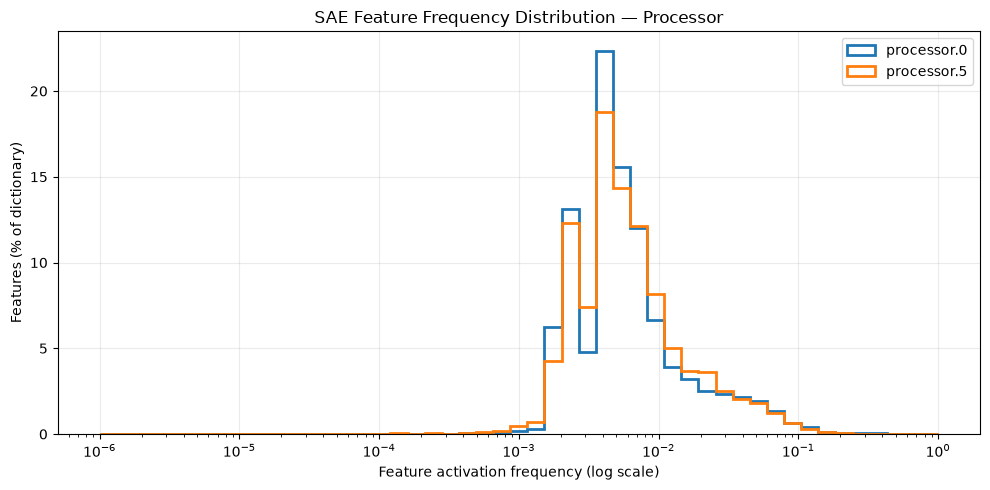

Saved: D:\bio_paper\pie-sae\results\sae_feature_analysis_independent\feature_statistics\figures\processor_frequency_distribution.png 

decoder.0     | Median=0.00825 | Inactive=0
decoder.3     | Median=0.00733 | Inactive=0


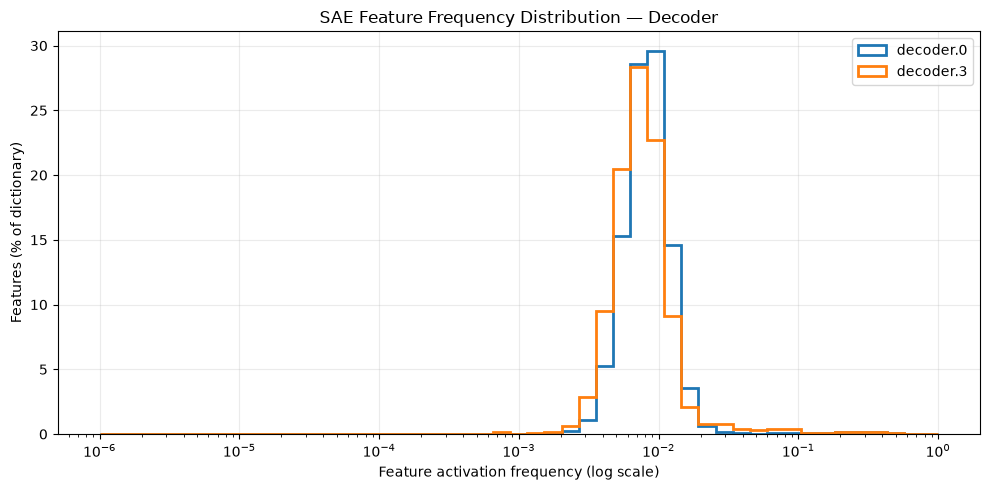

Saved: D:\bio_paper\pie-sae\results\sae_feature_analysis_independent\feature_statistics\figures\decoder_frequency_distribution.png 

Feature frequency distribution analysis completed.


In [17]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

STATS_DIR = (
    PROJECT_ROOT
    / "results"
    / "sae_feature_analysis_independent"
    / "feature_statistics"
)

FIGURE_DIR = STATS_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

comparisons = {
    "encoder": ("encoder.0", "encoder.3"),
    "processor": ("processor.0", "processor.5"),
    "decoder": ("decoder.0", "decoder.3"),
}

bins = np.logspace(-6, 0, 50)

for component, layers in comparisons.items():

    fig, ax = plt.subplots(figsize=(10, 5))

    for layer in layers:

        path = STATS_DIR / f"{layer.replace('.', '_')}.npz"

        assert path.is_file(), path

        with np.load(path) as data:
            frequencies = data["activation_frequency"].copy()

        assert frequencies.shape == (3072,)
        assert np.isfinite(frequencies).all()
        assert np.all((frequencies >= 0) & (frequencies <= 1))

        positive = frequencies[frequencies > 0]

        weights = np.full(
            len(positive),
            100.0 / len(frequencies),
        )

        ax.hist(
            positive,
            bins=bins,
            weights=weights,
            histtype="step",
            linewidth=2,
            label=layer,
        )

        print(
            f"{layer:<13} | "
            f"Median={np.median(frequencies):.5f} | "
            f"Inactive={(frequencies == 0).sum()}"
        )

    ax.set_xscale("log")

    ax.set_xlabel("Feature activation frequency (log scale)")
    ax.set_ylabel("Features (% of dictionary)")

    ax.set_title(
        f"SAE Feature Frequency Distribution — {component.capitalize()}"
    )

    ax.legend()
    ax.grid(alpha=0.25)

    fig.tight_layout()

    figure_path = (
        FIGURE_DIR
        / f"{component}_frequency_distribution.png"
    )

    fig.savefig(
        figure_path,
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)

    print("Saved:", figure_path, "\n")

print("Feature frequency distribution analysis completed.")

## 7. Biological Reference Data

Biological annotation requires external reference datasets.

The analysis follows the ontology and interaction-network
sources used in Kendiukhov's `04_annotate_features.py`:

- Gene Ontology Biological Process
- KEGG
- Reactome
- STRING
- TRRUST

Reference datasets must be identified and their provenance
recorded before enrichment analysis.

### 7.1. Reference Gene Set Acquisition

Human gene sets for GO Biological Process, KEGG, and
Reactome are obtained from versioned Enrichr libraries.

The downloaded source data and conversion metadata are
preserved to support reproducible enrichment analysis.

STRING and TRRUST interaction networks are handled separately.

In [19]:
import json
import hashlib
from pathlib import Path
from datetime import datetime, timezone
from urllib.request import Request, urlopen
from urllib.parse import urlencode

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

REFERENCE_DIR = PROJECT_ROOT / "data" / "biological_references"
REFERENCE_DIR.mkdir(parents=True, exist_ok=True)

LIBRARIES = {
    "GO_BP": (
        "GO_Biological_Process_2025",
        "go_bp_gene_sets.json",
    ),
    "KEGG": (
        "KEGG_2021_Human",
        "kegg_gene_sets.json",
    ),
    "Reactome": (
        "Reactome_2022",
        "reactome_gene_sets.json",
    ),
}

provenance = {}

for source, (library_name, filename) in LIBRARIES.items():

    url = (
        "https://maayanlab.cloud/Enrichr/geneSetLibrary?"
        + urlencode({
            "mode": "text",
            "libraryName": library_name,
        })
    )

    raw_path = REFERENCE_DIR / f"{library_name}.txt"
    output_path = REFERENCE_DIR / filename

    print(f"\nPreparing {source}: {library_name}")

    if raw_path.exists():
        raw = raw_path.read_bytes()
        print("Using existing downloaded source.")
    else:
        request = Request(
            url,
            headers={"User-Agent": "PIE-SAE-Research/1.0"},
        )

        with urlopen(request, timeout=120) as response:
            raw = response.read()

        assert raw, f"Empty response: {library_name}"

        raw_path.write_bytes(raw)
        print("Downloaded source data.")

    # Enrichr text libraries contain:
    # term, description, gene1, gene2, ...
    gene_sets = {}

    for line in raw.decode("utf-8").splitlines():

        fields = line.rstrip("\r\n").split("\t")

        if len(fields) < 3:
            continue

        term = fields[0].strip()

        genes = sorted({
            field.split(",")[0].strip().upper()
            for field in fields[2:]
            if field.strip()
        })

        if term and genes:
            gene_sets[term] = genes

    assert len(gene_sets) > 0, (
        f"No gene sets parsed: {library_name}"
    )

    with open(output_path, "w", encoding="utf-8") as f:
        json.dump(
            gene_sets,
            f,
            ensure_ascii=False,
            indent=2,
        )

    unique_genes = set()

    for genes in gene_sets.values():
        unique_genes.update(genes)

    provenance[source] = {
        "library": library_name,
        "source_url": url,
        "source_sha256": hashlib.sha256(raw).hexdigest(),
        "n_terms": len(gene_sets),
        "n_unique_genes": len(unique_genes),
        "output_file": filename,
    }

    print("Gene sets:", len(gene_sets))
    print("Unique genes:", len(unique_genes))
    print("Saved:", output_path.name)

provenance_path = REFERENCE_DIR / "provenance.json"

# Preserve existing STRING/TRRUST source records on repeated execution.
if provenance_path.is_file():
    previous_provenance = json.loads(provenance_path.read_text(encoding="utf-8"))
    preserved_sources = previous_provenance.get("sources", {})
    provenance = {**preserved_sources, **provenance}

with open(provenance_path, "w", encoding="utf-8") as f:
    json.dump(
        {
            "prepared_at_utc": datetime.now(
                timezone.utc
            ).isoformat(),
            "sources": provenance,
        },
        f,
        indent=2,
    )

required_sources = {
    "GO_BP",
    "KEGG",
    "Reactome",
    "TRRUST",
    "STRING",
}

assert required_sources.issubset(provenance), (
    f"Missing sources: {required_sources - set(provenance)}"
)

print("Verified reference sources:", sorted(provenance))

print("\nREFERENCE PREPARATION COMPLETED")
print("Prepared GO/KEGG/Reactome libraries: 3")
print("Provenance:", provenance_path)


Preparing GO_BP: GO_Biological_Process_2025
Using existing downloaded source.
Gene sets: 5343
Unique genes: 14674
Saved: go_bp_gene_sets.json

Preparing KEGG: KEGG_2021_Human
Using existing downloaded source.
Gene sets: 320
Unique genes: 8078
Saved: kegg_gene_sets.json

Preparing Reactome: Reactome_2022
Using existing downloaded source.
Gene sets: 1818
Unique genes: 10489
Saved: reactome_gene_sets.json
Verified reference sources: ['GO_BP', 'KEGG', 'Reactome', 'STRING', 'TRRUST']

REFERENCE PREPARATION COMPLETED
Prepared GO/KEGG/Reactome libraries: 3
Provenance: D:\bio_paper\pie-sae\data\biological_references\provenance.json


### 7.2. TRRUST Regulatory Network

The human TRRUST v2 database provides curated
transcription factor–target gene relationships.

The original bio-sae annotation pipeline uses these
relationships to characterize regulatory interactions
among genes associated with individual SAE features.

The original source file is preserved, and its checksum
is recorded for reproducibility.

In [20]:
import json
import hashlib
from pathlib import Path
from urllib.request import Request, urlopen

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

REFERENCE_DIR = PROJECT_ROOT / "data" / "biological_references"
REFERENCE_DIR.mkdir(parents=True, exist_ok=True)

TRRUST_URL = (
    "https://www.grnpedia.org/trrust/data/"
    "trrust_rawdata.human.tsv"
)

TRRUST_PATH = REFERENCE_DIR / "trrust_human.tsv"

# Download only if the source file is absent.
if not TRRUST_PATH.is_file():

    request = Request(
        TRRUST_URL,
        headers={"User-Agent": "PIE-SAE-Research/1.0"},
    )

    with urlopen(request, timeout=120) as response:
        raw = response.read()

    assert raw, "Empty TRRUST response"

    TRRUST_PATH.write_bytes(raw)

    print("TRRUST downloaded.")

else:
    raw = TRRUST_PATH.read_bytes()
    print("Using existing TRRUST file.")


# Validate the expected four-column format.
records = []

for line in raw.decode("utf-8").splitlines():

    if not line.strip():
        continue

    fields = line.split("\t")

    assert len(fields) == 4, (
        f"Unexpected TRRUST record: {fields}"
    )

    records.append(fields)

assert len(records) > 1000

transcription_factors = {
    row[0].upper() for row in records
}

target_genes = {
    row[1].upper() for row in records
}

checksum = hashlib.sha256(raw).hexdigest()


# Extend the existing provenance manifest.
provenance_path = REFERENCE_DIR / "provenance.json"

with open(provenance_path, encoding="utf-8") as f:
    provenance = json.load(f)

provenance["sources"]["TRRUST"] = {
    "database": "TRRUST v2",
    "species": "Homo sapiens",
    "source_url": TRRUST_URL,
    "source_sha256": checksum,
    "n_records": len(records),
    "n_transcription_factors": len(transcription_factors),
    "n_target_genes": len(target_genes),
    "output_file": TRRUST_PATH.name,
}

with open(provenance_path, "w", encoding="utf-8") as f:
    json.dump(provenance, f, indent=2)


print("\n" + "=" * 60)
print("TRRUST REFERENCE DATA")
print("=" * 60)

print("Regulatory records:", len(records))
print("Transcription factors:", len(transcription_factors))
print("Target genes:", len(target_genes))

print("\nFirst 5 records:")

for row in records[:5]:
    print(row)

print("\nSHA256:", checksum)
print("Saved:", TRRUST_PATH)

print("\nTRRUST preparation completed.")

Using existing TRRUST file.

TRRUST REFERENCE DATA
Regulatory records: 9396
Transcription factors: 795
Target genes: 2492

First 5 records:
['AATF', 'BAX', 'Repression', '22909821']
['AATF', 'CDKN1A', 'Unknown', '17157788']
['AATF', 'KLK3', 'Unknown', '23146908']
['AATF', 'MYC', 'Activation', '20549547']
['AATF', 'TP53', 'Unknown', '17157788']

SHA256: 9b909319ccc8e36588b5a1bd3640e0dfba03936c6fc154cc4304d742bec11bed
Saved: D:\bio_paper\pie-sae\data\biological_references\trrust_human.tsv

TRRUST preparation completed.


### 7.3. STRING Protein Association Network

Human protein associations were obtained from STRING v12.0.

STRING protein identifiers were mapped to gene symbols using
the corresponding protein information file.

The network was restricted to genes represented in the PIE
output vocabulary.

Undirected gene-level associations were retained at combined
confidence score thresholds of 700 and 900.

Original source files, checksums, mapping statistics, and
network provenance were preserved.

STRING functional associations are not necessarily direct
physical protein interactions.

In [21]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

SRC_DIR = PROJECT_ROOT / "src"

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from prepare_string_reference import prepare_string_reference


# Prepare STRING v12.0 human association network.
string_result = prepare_string_reference(
    project_root=PROJECT_ROOT,
)

print("\n" + "=" * 60)
print("STRING REFERENCE PREPARATION")
print("=" * 60)

print("Version:", string_result["version"])
print("Species:", string_result["species"])

print(
    "PIE genes mapped:",
    string_result["n_gene_symbols_mapped"],
)

print(
    "Gene pairs (score >=700):",
    string_result["n_pairs_700"],
)

print(
    "Gene pairs (score >=900):",
    string_result["n_pairs_900"],
)

print("\nSTRING preparation completed.")

Using existing download: 9606.protein.links.v12.0.txt.gz
Using existing download: 9606.protein.info.v12.0.txt.gz
PIE genes with matching STRING preferred name: 6492/6642
Existing output matches generated network; no overwrite.
STRING v12.0 human network prepared
Gene pairs at score >=700: 98733
Gene pairs at score >=900: 48705
Output: D:\bio_paper\pie-sae\data\biological_references\string_ppi_edges.json
Provenance: D:\bio_paper\pie-sae\data\biological_references\provenance.json

STRING REFERENCE PREPARATION
Version: 12.0
Species: Homo sapiens (9606)
PIE genes mapped: 6492
Gene pairs (score >=700): 98733
Gene pairs (score >=900): 48705

STRING preparation completed.


## 8. Biological Annotation of Decoder SAE Features

Feature-associated gene sets are evaluated against GO Biological
Process, KEGG, and Reactome using one-sided Fisher's exact tests.

The statistical background consists of the 6642 genes represented
in the PIE decoder output vocabulary. Terms containing 5–500
represented genes are considered.

Multiple-testing correction is performed using the
Benjamini–Hochberg procedure.

STRING and TRRUST interactions are analyzed separately.
STRING associations are treated as undirected, whereas
TRRUST regulatory interactions retain their direction.

Network edge counts are descriptive and are not interpreted
as statistically significant enrichment without a null model.

### 8.1. Biological Annotation Across Decoder Layers

Functional enrichment analysis is extended to all four
PIE decoder blocks using the independently initialized
SAEs and their training-set feature–gene catalogs.

The same annotation databases, gene background, term-size
filters, significance threshold, and multiple-testing
procedure are applied to every layer.

STRING and TRRUST network statistics are reported
separately from functional enrichment results.

In [22]:
import csv
import json
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

SRC_DIR = PROJECT_ROOT / "src"

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from sae_biological_annotation import annotate_decoder_layer

ANNOTATION_DIR = (
    PROJECT_ROOT
    / "results"
    / "sae_feature_analysis_independent"
    / "biological_annotations"
)

for layer_index in range(4):

    print("\n" + "=" * 60)
    print(f"BIOLOGICAL ANNOTATION — decoder.{layer_index}")
    print("=" * 60)

    annotate_decoder_layer(
        project_root=PROJECT_ROOT,
        layer_index=layer_index,
        alpha=0.05,
        min_term_size=5,
        max_term_size=500,
        min_overlap=2,
    )


# Consolidate results from all four decoder layers.
rows = []

for layer_index in range(4):

    path = (
        ANNOTATION_DIR
        / f"decoder_{layer_index}_annotations.json"
    )

    assert path.is_file(), path

    with open(path, encoding="utf-8") as f:
        data = json.load(f)

    summary = data["summary"]

    assert summary["n_features"] == 3072

    rows.append({
        "layer": f"decoder.{layer_index}",
        "features": summary["n_features"],
        "annotated_features":
            summary["n_features_with_significant_annotation"],
        "significant_associations":
            summary["n_significant_feature_term_associations"],
        "GO_BP": summary["significant_by_source"].get("GO_BP", 0),
        "KEGG": summary["significant_by_source"].get("KEGG", 0),
        "Reactome": summary["significant_by_source"].get("Reactome", 0),
        "TRRUST_TF": summary["significant_by_source"].get("TRRUST_TF", 0),
    })


summary_path = ANNOTATION_DIR / "decoder_annotation_summary.csv"

with open(summary_path, "w", newline="", encoding="utf-8") as f:

    writer = csv.DictWriter(
        f,
        fieldnames=list(rows[0].keys()),
    )

    writer.writeheader()
    writer.writerows(rows)


print("\n" + "=" * 75)
print("BIOLOGICAL ANNOTATION — ALL DECODER LAYERS")
print("=" * 75)

print(
    f"{'Layer':<13}"
    f"{'Annotated':>12}"
    f"{'Associations':>16}"
)

for row in rows:
    print(
        f"{row['layer']:<13}"
        f"{row['annotated_features']:>12}"
        f"{row['significant_associations']:>16}"
    )

assert len(rows) == 4

print("\nAll four decoder layers annotated successfully.")
print("Summary saved to:", summary_path)


BIOLOGICAL ANNOTATION — decoder.0
Annotating decoder.0: 3072 features, 4422 eligible annotation terms, background=6642 PIE genes
  Features: 512/3072
  Features: 1024/3072
  Features: 1536/3072
  Features: 2048/3072
  Features: 2560/3072
  Features: 3072/3072
Verified existing annotations; skipping recomputation: D:\bio_paper\pie-sae\results\sae_feature_analysis_independent\biological_annotations\decoder_0_annotations.json

BIOLOGICAL ANNOTATION — decoder.1
Annotating decoder.1: 3072 features, 4422 eligible annotation terms, background=6642 PIE genes
  Features: 512/3072
  Features: 1024/3072
  Features: 1536/3072
  Features: 2048/3072
  Features: 2560/3072
  Features: 3072/3072
Verified existing annotations; skipping recomputation: D:\bio_paper\pie-sae\results\sae_feature_analysis_independent\biological_annotations\decoder_1_annotations.json

BIOLOGICAL ANNOTATION — decoder.2
Annotating decoder.2: 3072 features, 4422 eligible annotation terms, background=6642 PIE genes
  Features: 51

### 8.2. Functional Annotation Across Decoder Layers

We compare the proportion of SAE features with at least one
statistically significant functional annotation across the
four PIE decoder blocks.

The same enrichment procedure, reference databases,
background gene universe, and significance threshold
are used for all layers.

The analysis characterizes the distribution of functional
annotations across decoder depth. Statistical enrichment
does not by itself establish mechanistic interpretability.

BIOLOGICAL ANNOTATION ACROSS DECODER LAYERS
decoder.0    | Annotated: 1694/3072 | Fraction: 55.14% | Associations: 18976
decoder.1    | Annotated: 1616/3072 | Fraction: 52.60% | Associations: 18144
decoder.2    | Annotated: 1603/3072 | Fraction: 52.18% | Associations: 18321
decoder.3    | Annotated: 1612/3072 | Fraction: 52.47% | Associations: 18323


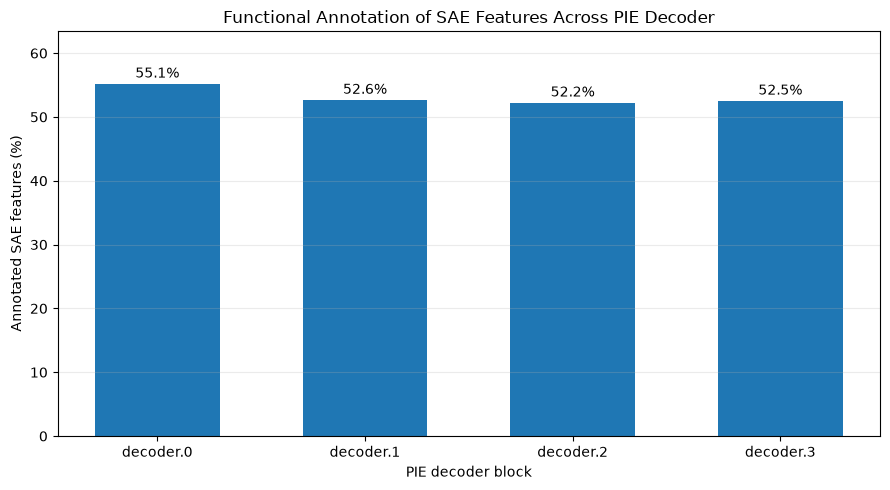


Figure saved: D:\bio_paper\pie-sae\results\sae_feature_analysis_independent\biological_annotations\annotation_fraction_by_layer.png
Annotation comparison completed.


In [23]:
import csv
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

ANNOTATION_DIR = (
    PROJECT_ROOT
    / "results"
    / "sae_feature_analysis_independent"
    / "biological_annotations"
)

summary_path = ANNOTATION_DIR / "decoder_annotation_summary.csv"

assert summary_path.is_file()

with open(summary_path, newline="", encoding="utf-8") as f:
    rows = list(csv.DictReader(f))

assert len(rows) == 4

rows = sorted(rows, key=lambda r: int(r["layer"].split(".")[1]))

layers = [row["layer"] for row in rows]

total_features = np.array([
    int(row["features"]) for row in rows
])

annotated_features = np.array([
    int(row["annotated_features"]) for row in rows
])

significant_associations = np.array([
    int(row["significant_associations"]) for row in rows
])

assert np.all(total_features == 3072)
assert np.all(annotated_features <= total_features)

fractions = 100 * annotated_features / total_features

print("=" * 65)
print("BIOLOGICAL ANNOTATION ACROSS DECODER LAYERS")
print("=" * 65)

for i, layer in enumerate(layers):
    print(
        f"{layer:<12} | "
        f"Annotated: {annotated_features[i]:>4}/3072 | "
        f"Fraction: {fractions[i]:>5.2f}% | "
        f"Associations: {significant_associations[i]}"
    )

# --------------------------------------------------
# Visualization
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(layers, fractions, width=0.6)

for bar, value in zip(bars, fractions):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{value:.1f}%",
        ha="center",
        va="bottom",
    )

ax.set_xlabel("PIE decoder block")
ax.set_ylabel("Annotated SAE features (%)")

ax.set_title(
    "Functional Annotation of SAE Features Across PIE Decoder"
)

ax.set_ylim(0, max(fractions.max() * 1.15, 10))
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()

figure_path = (
    ANNOTATION_DIR / "annotation_fraction_by_layer.png"
)

fig.savefig(figure_path, dpi=200, bbox_inches="tight")

plt.show()
plt.close(fig)

print("\nFigure saved:", figure_path)
print("Annotation comparison completed.")

### 8.3. Gene-Label Permutation Controls

We evaluate whether the observed functional annotation
of decoder SAE features exceeds a gene-label permutation
baseline.

Each permutation preserves feature gene-set sizes,
gene occurrence frequencies, and overlaps between
feature-associated gene sets.

Functional enrichment is recomputed using the original
statistical procedure and multiple-testing correction.

This control tests gene-set coherence under a defined
null model. It does not establish causal biological
mechanisms or perturbation-dependent regulatory logic.

#### Permutation procedure

The gene-label permutation analysis is extended to all four
decoder blocks using the same reference databases, statistical
tests, and randomization procedure.

Each experiment uses 100 independent permutations of the
gene vocabulary.

Observed functional enrichment is compared with the null
distribution of annotated features and significant
feature–term associations.

The analysis evaluates functional coherence of the
feature-associated gene sets, without establishing
perturbation-dependent regulatory mechanisms.

In [24]:
import csv
from pathlib import Path

from sae_annotation_null import run_annotation_permutation_control

# --------------------------------------------------
# Permutation controls for all decoder layers
# --------------------------------------------------

control_results = []

for layer_index in range(4):

    layer = f"decoder.{layer_index}"

    print("\n" + "=" * 65)
    print(f"GENE-LABEL PERMUTATION CONTROL — {layer}")
    print("=" * 65)

    result = run_annotation_permutation_control(
        project_root=PROJECT_ROOT,
        layer_index=layer_index,
        n_permutations=100,
        seed=42,
    )

    observed = result["observed"]
    null = result["summary"]

    control_results.append({
        "layer": layer,
        "observed_annotated": observed["annotated_features"],
        "null_mean_annotated": null["null_mean_annotated"],
        "observed_associations": observed["significant_associations"],
        "null_mean_associations": null["null_mean_associations"],
        "empirical_p": null["empirical_p_annotated"],
    })

    print(
        f"{layer} | "
        f"Observed={observed['annotated_features']} | "
        f"Null mean={null['null_mean_annotated']:.3f} | "
        f"p={null['empirical_p_annotated']:.4f}"
    )


# --------------------------------------------------
# Save summary
# --------------------------------------------------

assert len(control_results) == 4

output_dir = (
    PROJECT_ROOT
    / "results"
    / "sae_feature_analysis_independent"
    / "annotation_controls"
)

output_dir.mkdir(parents=True, exist_ok=True)

summary_path = output_dir / "all_decoder_controls.csv"

with open(summary_path, "w", newline="", encoding="utf-8") as f:

    writer = csv.DictWriter(
        f,
        fieldnames=list(control_results[0].keys()),
    )

    writer.writeheader()
    writer.writerows(control_results)


print("\n" + "=" * 75)
print("FUNCTIONAL ANNOTATION CONTROLS — ALL DECODER LAYERS")
print("=" * 75)

for row in control_results:

    print(
        f"{row['layer']:<12} | "
        f"Observed: {row['observed_annotated']:>4} | "
        f"Null mean: {row['null_mean_annotated']:.3f} | "
        f"p={row['empirical_p']:.4f}"
    )

print("\nAll decoder controls completed.")
print("Summary:", summary_path)


GENE-LABEL PERMUTATION CONTROL — decoder.0
Reusing verified null control: D:\bio_paper\pie-sae\results\sae_feature_analysis_independent\annotation_controls\decoder_0_gene_permutation_100_seed42.json
decoder.0 | Observed=1694 | Null mean=0.010 | p=0.0099

GENE-LABEL PERMUTATION CONTROL — decoder.1
Reusing verified null control: D:\bio_paper\pie-sae\results\sae_feature_analysis_independent\annotation_controls\decoder_1_gene_permutation_100_seed42.json
decoder.1 | Observed=1616 | Null mean=0.040 | p=0.0099

GENE-LABEL PERMUTATION CONTROL — decoder.2
Reusing verified null control: D:\bio_paper\pie-sae\results\sae_feature_analysis_independent\annotation_controls\decoder_2_gene_permutation_100_seed42.json
decoder.2 | Observed=1603 | Null mean=0.000 | p=0.0099

GENE-LABEL PERMUTATION CONTROL — decoder.3
Reusing verified null control: D:\bio_paper\pie-sae\results\sae_feature_analysis_independent\annotation_controls\decoder_3_gene_permutation_100_seed42.json
decoder.3 | Observed=1612 | Null me

## 9. Conclusions and limitations

The analysis used the final independently initialized series of 14 SAE dictionaries, with 3072 features and TopK=32 per layer. The experimental inputs were 128 training and 32 held-out validation perturbation conditions from the PIE K562 held-out-context configuration. No new PIE inference or SAE training was performed.

**Dictionary geometry and activation statistics.** Mean absolute cosine similarity and feature-usage inequality varied across the encoder, processor, and decoder. SVD comparison showed that **200 out of 43,008** dictionary directions exceeded an absolute cosine similarity of 0.5 with one of the top 50 singular directions, and **20** exceeded 0.7. Axis-wise alignment does not measure overlap with the full leading singular *subspace*.

**Decoder feature–gene associations.** All four decoder layers produced top-20 gene catalogs for 3072 features each. Training and validation catalogs exhibited high overlap. For leading feature–gene associations, firing was commonly observed across nearly all conditions. Consequently, these associations may largely reflect stable output-gene identity or gene embeddings, rather than responses specific to perturbations. Feature activation *magnitudes* and downstream causal effects have not been established to be condition-invariant.

**Functional annotation.** Under the specified per-decoder-layer BH procedure, the proportion of decoder features with at least one significant GO BP, KEGG, Reactome or curated TF association was **55.14%** (`decoder.0`), **52.60%** (`decoder.1`), **52.18%** (`decoder.2`) and **52.47%** (`decoder.3`). STRING and directed TRRUST network edge counts were descriptive, not independently tested for enrichment. Functional annotation is not evidence of a causal regulatory mechanism.

**Gene-label permutation control.** With 100 global label permutations per decoder layer, the observed number of annotated features was far above the chosen null, with empirical \(p=1/101pprox0.0099\) in each layer. These controls preserve gene-list size and cross-feature overlap structure, but do not preserve gene-specific annotation degree, properties of the original pretrained gene embeddings, or perturbation effects. Their evidence is relative to this defined null only. The p-value resolution is limited by the number of permutations.

**Statistical scope.** Benjamini–Hochberg correction was performed within each decoder layer across all prespecified feature–term tests. All results describe a finite sample of experimental conditions; gene-position vectors within an individual condition are not independent experimental replicates. Training and validation catalogs were compared for the *same trained SAE*; reproducibility of individual features across independently trained SAE dictionaries remains untested. Due to their latent-slot semantics, encoder and processor vectors are not directly indexed by output genes and were not subjected to the decoder gene-catalog analysis.

The resulting catalogs, annotations, model-checkpoint manifest and saved feature statistics are inputs for the subsequent cross-layer analysis. Feature correspondence and causal intervention experiments are separate research questions.
